In [1]:
%matplotlib widget

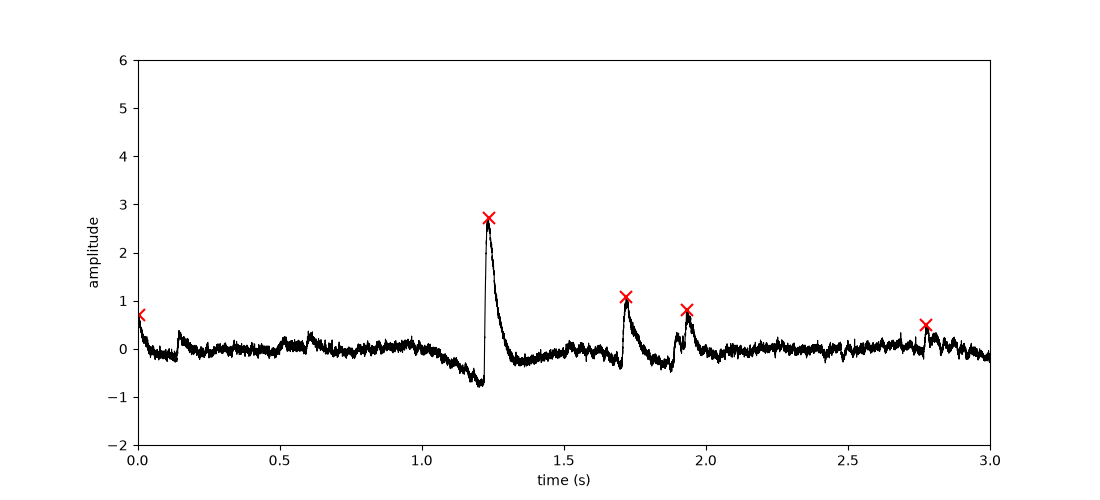

In [4]:
# Mini event detection + manual curation

# RUN THIS IN THE FIRST CELL OF THE NOTEBOOK, BY ITSELF:
#     %matplotlib widget
# (requires ipympl:  pip install ipympl   /   conda install -c conda-forge ipympl)

# Controls:
#   left click            -> add a peak (snaps to the local max near the click)
#   shift + left click    -> delete the nearest peak
#   right click           -> delete the nearest peak (if the browser allows it)
#   Undo button           -> reverts the last manual edit

import os
import csv
import numpy as np
import pyabf #will have to install pyabf for this program to run.
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
import ipywidgets as widgets
from IPython.display import display
import plotly.graph_objects as go #will have to install plotly for the scrollable full-trace export: pip install plotly

#configuration
DATA_DIR = 'C:/Users/12039/Documents/Sulk Projects/Voltage Project/Kir21-HS-FLP/Kir21-HS-FLP'
ABF_FILE = "Kir-HS-FLP-3Hrs-Animal2-A2-L-Minis.abf"

# all generated files (events csv, summary, full-trace plot) go in here
OUTPUT_DIR = os.path.join(DATA_DIR, os.path.splitext(ABF_FILE)[0] + "_output")
os.makedirs(OUTPUT_DIR, exist_ok=True)

DATA_CUTOFF_HZ     = 5000    # low-pass for the signal
BASELINE_CUTOFF_HZ = 2       # low-pass that defines the drifting baseline
FILTER_ORDER       = 2

HEIGHT_MULTIPLIER  = 0.1     # fraction of max(trace) used as the height floor
PROMINENCE         = 0.3
MIN_DISTANCE       = 500     # samples
WIDTH_RANGE        = (0, 1800)

WINDOW_S   = 3.0             # width of the scrolling view
Y_LIMITS   = (-2, 6)
SNAP_MS    = 3.0             # click -> local max search radius when adding
PICK_MS    = 5.0             # click -> peak search radius when deleting
MATCH_MS   = 2.0             # tolerance used to match peaks across re-detection

# ------------------------------- load data ---------------------------------
abf = pyabf.ABF(os.path.join(DATA_DIR, ABF_FILE))
fs  = abf.dataRate
nyq = 0.5 * fs

y = np.asarray(abf.data[0], dtype=float)
t = np.arange(y.size) / fs          # built from dataRate, so it always matches y

# ------------------------------- filtering ---------------------------------
b_d, a_d = butter(FILTER_ORDER, DATA_CUTOFF_HZ / nyq, btype='low')
b_b, a_b = butter(FILTER_ORDER, BASELINE_CUTOFF_HZ / nyq, btype='low')

trace = filtfilt(b_d, a_d, y) - filtfilt(b_b, a_b, y)

n         = trace.size
snap_n    = max(1, int(SNAP_MS  * fs / 1000))
pick_n    = max(1, int(PICK_MS  * fs / 1000))
match_n   = max(1, int(MATCH_MS * fs / 1000))
duration  = t[-1] - t[0]

# ---------------------------- peak bookkeeping -----------------------------
auto_peaks     = np.array([], dtype=int)   # whatever find_peaks last returned
manual_added   = set()                     # indices the user added by hand
manual_removed = set()                     # indices the user deleted by hand
peaks          = np.array([], dtype=int)   # the working set actually plotted
history        = []                        # ('add'|'remove', index) for Undo


def _nearest(idx, pool, tol):
    """Closest member of `pool` to `idx`, or None if nothing is within `tol`."""
    pool = np.asarray(sorted(pool), dtype=int)
    if pool.size == 0:
        return None
    j = int(np.argmin(np.abs(pool - idx)))
    return int(pool[j]) if abs(pool[j] - idx) <= tol else None


def detect_peaks(mult, prom):
    """Run automatic detection. Manual edits are preserved on top of it."""
    global auto_peaks
    height = np.max(trace) * mult
    found, _ = find_peaks(trace,
                          height=height,
                          prominence=prom,
                          distance=MIN_DISTANCE,
                          width=WIDTH_RANGE)
    auto_peaks = found
    rebuild()


def rebuild():
    """peaks = (auto peaks the user didn't veto) + (peaks the user added)."""
    global peaks
    kept = [p for p in auto_peaks
            if _nearest(p, manual_removed, match_n) is None]
    merged = sorted(set(kept))
    for p in sorted(manual_added):
        if _nearest(p, merged, match_n) is None:
            merged.append(p)
    peaks = np.array(sorted(merged), dtype=int)


def add_peak(click_x):
    """Snap a click to the local maximum around it and add that sample."""
    c  = int(round(click_x * fs))
    lo = max(0, c - snap_n)
    hi = min(n, c + snap_n + 1)
    if hi <= lo:
        return None
    idx = lo + int(np.argmax(trace[lo:hi]))
    if _nearest(idx, peaks, pick_n) is not None:
        return None                       # a peak is already marked there
    manual_added.add(idx)
    manual_removed.discard(idx)
    rebuild()
    return idx


def remove_peak(click_x):
    """Delete the marked peak nearest the click."""
    c   = int(round(click_x * fs))
    hit = _nearest(c, peaks, pick_n)
    if hit is None:
        return None
    manual_added.discard(hit)
    manual_removed.add(hit)
    rebuild()
    return hit


def undo():
    if not history:
        return
    action, idx = history.pop()
    if action == 'add':
        manual_added.discard(idx)
    else:
        manual_removed.discard(idx)
    rebuild()


# ------------------------------- statistics --------------------------------
def stats_text():
    if peaks.size == 0:
        return "No peaks."
    amps = trace[peaks]
    return (f"n peaks        : {peaks.size}   "
            f"(auto {peaks.size - len(manual_added)}, "
            f"added {len(manual_added)}, removed {len(manual_removed)})\n"
            f"frequency      : {peaks.size / duration:.2f} events/s "
            f"over {duration:.1f} s\n"
            f"amplitude mean : {np.mean(amps):.2f}\n"
            f"amplitude sd   : {np.std(amps, ddof=1):.2f}\n"
            f"amplitude med  : {np.median(amps):.2f}\n"
            f"amplitude IQR  : {np.percentile(amps, 25):.2f} - "
            f"{np.percentile(amps, 75):.2f}")


# --------------------------------- figure ----------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
fig.canvas.header_visible = False
fig.canvas.footer_visible = False
(line,) = ax.plot([], [], 'k', lw=0.8)
(marks,) = ax.plot([], [], 'x', color='red', ms=8, mew=1.5, ls='none')
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")

out = widgets.Output()


def redraw():
    start = float(slider.value)
    i0 = max(0, int(start * fs))
    i1 = min(n, int((start + WINDOW_S) * fs))
    line.set_data(t[i0:i1], trace[i0:i1])          # only the visible slice
    vis = peaks[(peaks >= i0) & (peaks < i1)]
    marks.set_data(t[vis], trace[vis])
    ax.set_xlim(start, start + WINDOW_S)
    ax.set_ylim(*Y_LIMITS)
    fig.canvas.draw_idle()
    out.clear_output(wait=True)
    with out:
        print(stats_text())


def on_click(event):
    if event.inaxes is not ax or event.xdata is None:
        return
    tb = getattr(fig.canvas, "toolbar", None)
    if tb is not None and getattr(tb, "mode", "") not in ("", None):
        return                                     # zoom/pan is active
    deleting = (event.button == 3) or (event.key == 'shift')
    idx = remove_peak(event.xdata) if deleting else add_peak(event.xdata)
    if idx is not None:
        history.append(('remove' if deleting else 'add', idx))
        redraw()


fig.canvas.mpl_connect('button_press_event', on_click)

# -------------------------------- controls ---------------------------------
slider = widgets.FloatSlider(min=0, max=max(0.0, duration - WINDOW_S),
                             step=0.1, value=0, description='start (s)',
                             continuous_update=False, readout_format='.1f',
                             style={'description_width': 'initial'},
                             layout=widgets.Layout(width='600px'))
mult_w = widgets.FloatSlider(min=0.0, max=1.0, step=0.01,
                             value=HEIGHT_MULTIPLIER, description='height x max',
                             continuous_update=False,
                             style={'description_width': 'initial'})
prom_w = widgets.FloatSlider(min=0.0, max=3.0, step=0.05, value=PROMINENCE,
                             description='prominence', continuous_update=False,
                             style={'description_width': 'initial'})

prev_b  = widgets.Button(description='< prev')
next_b  = widgets.Button(description='next >')
undo_b  = widgets.Button(description='Undo', button_style='warning')
reset_b = widgets.Button(description='Clear manual edits')
save_b  = widgets.Button(description='Save Results', button_style='success')

prev_b.on_click(lambda _: setattr(slider, 'value',
                                  max(slider.min, slider.value - WINDOW_S)))
next_b.on_click(lambda _: setattr(slider, 'value',
                                  min(slider.max, slider.value + WINDOW_S)))
undo_b.on_click(lambda _: (undo(), redraw()))


def _reset(_):
    manual_added.clear()
    manual_removed.clear()
    history.clear()
    rebuild()
    redraw()


def _redetect(_):
    detect_peaks(mult_w.value, prom_w.value)
    redraw()


def _save(_):
    stem = os.path.splitext(ABF_FILE)[0]
    events_path = os.path.join(OUTPUT_DIR, f"{stem}_events.csv")
    # kept peaks (currently plotted) + anything the user manually removed,
    # so the 'removed' column actually has something to report on.
    all_idx = sorted(set(peaks.tolist()) | manual_removed)
    with open(events_path, 'w', newline='') as fh:
        w = csv.writer(fh)
        w.writerow(['sample', 'time_s', 'amplitude', 'source', 'removed'])
        for p in all_idx:
            removed = p in manual_removed
            src = 'manual' if _nearest(p, manual_added, 0) is not None else 'auto'
            w.writerow([p, f"{t[p]:.6f}", f"{trace[p]:.6f}", src, removed])
    with open(os.path.join(OUTPUT_DIR, f"{stem}_summary.txt"), 'w') as fh:
        fh.write(f"file: {ABF_FILE}\n")
        fh.write(f"height_multiplier: {mult_w.value}\nprominence: {prom_w.value}\n")
        fh.write(f"distance: {MIN_DISTANCE}\nwidth: {WIDTH_RANGE}\n")
        fh.write(f"manual_added: {sorted(manual_added)}\n")
        fh.write(f"manual_removed: {sorted(manual_removed)}\n\n")
        fh.write(stats_text() + "\n")
    with out:
        print(f"\nsaved -> {events_path}")


def _save_full_plot(_):
    """Export the ENTIRE trace as a standalone, scrollable HTML plot.
    The toolbar's built-in 'Download plot' button only captures whatever is
    currently visible in the WINDOW_S-wide view, so this instead builds a
    Plotly figure with a range-slider: opening the saved .html file in any
    browser lets you drag the slider (or scroll-zoom) to pan through the
    full recording, with no Python/Jupyter required."""
    stem = os.path.splitext(ABF_FILE)[0]
    full_plot_path = os.path.join(OUTPUT_DIR, f"{stem}_full_trace.html")

    fig2 = go.Figure()
    fig2.add_trace(go.Scattergl(x=t, y=trace, mode='lines',
                                 line=dict(color='black', width=0.8),
                                 name='trace'))
    if peaks.size:
        fig2.add_trace(go.Scatter(x=t[peaks], y=trace[peaks], mode='markers',
                                   marker=dict(color='red', symbol='x', size=8,
                                               line=dict(width=1.5)),
                                   name='peaks'))
    fig2.update_layout(
        xaxis=dict(title='time (s)', range=[0, WINDOW_S],
                   rangeslider=dict(visible=True)),
        yaxis=dict(title='amplitude', range=list(Y_LIMITS)),
        showlegend=False,
        margin=dict(l=60, r=20, t=30, b=40),
    )
    fig2.write_html(full_plot_path, include_plotlyjs='cdn')

    with out:
        print(f"\nsaved scrollable full-trace plot -> {full_plot_path}")


reset_b.on_click(_reset)


def _save_results(_):
    _save(_)
    _save_full_plot(_)


save_b.on_click(_save_results)
slider.observe(lambda ch: redraw(), names='value')
mult_w.observe(_redetect, names='value')
prom_w.observe(_redetect, names='value')

display(widgets.VBox([
    out,
    widgets.HBox([prev_b, slider, next_b]),
    widgets.HBox([mult_w, prom_w]),
    widgets.HBox([undo_b, reset_b, save_b]),
    widgets.HTML("<i>left click = add &nbsp;|&nbsp; shift+click or right click "
                 "= delete</i>"),
]))

detect_peaks(HEIGHT_MULTIPLIER, PROMINENCE)
redraw()